<a href="https://colab.research.google.com/github/FrancisLa/Langues_de_specialite/blob/main/chaine/05_analyse/exemple/analyse_exemple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Séance 6 — Analyser un corpus : thèmes, variables, visualisation et recherche d’information

Langues de spécialité — Francis Lareau

Ce notebook reprend les fichiers enregistrés à la séance 5 : le tableau des articles, le vocabulaire et les deux matrices (comptage et TF-IDF). Nous avançons dans cet ordre :

**charger → décrire → analyser les thèmes → comparer selon une variable → visualiser → rechercher → sauvegarder**

Chaque analyse reçoit un identifiant et un statut, comme dans le README de l’étape `05_analyse` :

| ID | Analyse | Statut |
|---|---|---|
| A01 | Description du corpus et visualisations de base | Descriptive |
| A02 | Analyse thématique | Principale (si elle répond à votre question) |
| A03 | Thèmes selon une variable (auteurs, numéros, années) | Secondaire |
| A04 | Recherche d’information | Exploratoire |

**Principe de lecture.** Un poids, une fréquence ou un score oriente l’attention ; il ne démontre pas un thème. Le chemin est toujours :

`score ou fréquence → candidats → retour aux textes → interprétation prudente`

**À retenir avant de commencer.**
- Les valeurs de paramètres (nombre de thèmes, seuils, mots de la requête) sont des exemples. Vous devez justifier les vôtres.
- Aucune sortie affichée par ce notebook n’est un résultat de recherche tant que vous n’avez pas contrôlé les données, les paramètres et les textes.
- Un notebook exploratoire ne remplace pas une procédure documentée : les résultats que vous retiendrez devront pouvoir être reproduits et seront contrôlés à l’étape 06.

## 1. Ouvrir les données de la séance 5

### 1.1. Charger les bibliothèques

Une bibliothèque fournit des outils déjà écrits. Ici :
- `pandas` : lire et manipuler les tableaux ;
- `numpy` : calculer sur des vecteurs et des matrices ;
- `scipy.sparse` : lire les matrices creuses ;
- `scikit-learn` : modèle thématique, projection, pondération et similarité ;
- `matplotlib` : produire des figures ;
- `re` : chercher des motifs dans les textes ;
- `spaCy` : retrouver, dans la section 7, les lemmes d’un texte pour lire les mots de la requête dans leur contexte.

In [101]:
# À exécuter seulement si une bibliothèque manque :
# %pip install pandas numpy scipy scikit-learn matplotlib spacy
# !python -m spacy download fr_core_news_sm

from pathlib import Path
from datetime import datetime
from html import escape
import platform
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.stats import chi2 as loi_chi2
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display, HTML

import spacy
nlp = spacy.load("fr_core_news_sm")

# Afficher des textes un peu plus longs dans les tableaux.
#pd.set_option("display.max_colwidth", 90)

### 1.2. Indiquer l’environnement de travail

Reprendre le choix fait à la séance 5. Modifier seulement `IS_LOCAL` et, si vous travaillez sur votre ordinateur, le chemin de `root_path`.

In [102]:
# 1.2 Environnement de travail

# True  : vous travaillez sur votre propre ordinateur.
# False : vous travaillez dans Google Colab.
IS_LOCAL = True

if IS_LOCAL:
    # À adapter selon l’emplacement de Google Drive sur votre ordinateur.
    # Exemple Windows : Path("G:/Mon disque")
    # Exemple macOS : Path("/Users/VotreNom/Google Drive/My Drive")
    # Exemple Linux : Path("/home/VotreNom/GoogleDrive")
    root_path = Path("C:/Users/franc/My Drive")

else:
    # Charger la bibliothèque permettant d’accéder à Google Drive.
    from google.colab import drive

    # Connecter votre Google Drive à Colab.
    drive.mount("/content/drive")

    # Dans Colab, votre Drive est accessible à cet emplacement.
    root_path = Path("/content/drive/MyDrive")

print("Date :", datetime.now().strftime("%Y-%m-%d %H:%M"))
print("Système :", platform.system())
print("Version de Python :", sys.version.split()[0])
print("Environnement :", "local" if IS_LOCAL else "Google Colab")
print("Racine de Google Drive :", root_path)

Date : 2026-11-19 17:48
Système : Windows
Version de Python : 3.12.10
Environnement : local
Racine de Google Drive : C:\Users\franc\My Drive


### 1.3. Indiquer les dossiers et les fichiers

Nous lisons les fichiers sauvegardés à la séance 5 dans `donnees/preparees/`. Nous écrivons nos sorties dans `chaine/05_analyse/sorties_intermediaires/` : ce dossier reçoit des résultats dont le statut n’est pas encore établi. Les tableaux et figures finaux iront dans `resultats/` seulement après contrôle.

Les noms de fichiers ci-dessous sont ceux du notebook de la séance 5. Remplacez-les par les vôtres si vous avez choisi d’autres noms.

La cellule s’arrête avec un message si un fichier est introuvable : mieux vaut corriger le chemin que travailler sur un mauvais fichier.

In [103]:
# 1.3 Dossiers et chemins d'accès

project_folder = "Langues_de_specialite"
project_path = root_path / "GitHub" / project_folder

entree_path = project_path / "donnees" / "preparees"
sortie_path = project_path / "chaine" / "05_analyse" / "sorties_intermediaires"

fichier_data = entree_path / "AAD_dataframe_partial_inventory_with_texts.pkl"
fichier_vocabulaire = entree_path / "AAD_vocabulaire.csv"
fichier_comptage = entree_path / "AAD_matrice_comptage.npz"
fichier_tfidf = entree_path / "AAD_matrice_tfidf.npz"

for chemin in [fichier_data, fichier_vocabulaire, fichier_comptage, fichier_tfidf]:
    if chemin.is_file():
        print("Fichier trouvé :", chemin.name)
    else:
        raise FileNotFoundError(f"Fichier introuvable : {chemin}")

# Créer le dossier de sortie s'il n'existe pas.
sortie_path.mkdir(parents=True, exist_ok=True)
print("Dossier de sortie :", sortie_path)

Fichier trouvé : AAD_dataframe_partial_inventory_with_texts.pkl
Fichier trouvé : AAD_vocabulaire.csv
Fichier trouvé : AAD_matrice_comptage.npz
Fichier trouvé : AAD_matrice_tfidf.npz
Dossier de sortie : C:\Users\franc\My Drive\GitHub\Langues_de_specialite\chaine\05_analyse\sorties_intermediaires


### 1.4. Lire le tableau, le vocabulaire et les matrices

Nous lisons le dataframe enregistré dans le fichier Pickle de la séance 5, ainsi que le vocabulaire et les matrices de comptage et TF-IDF.

In [104]:
df = pd.read_pickle(fichier_data)
#df = df.reset_index(drop=True)

vocabulaire_df = pd.read_csv(fichier_vocabulaire, keep_default_na=False)
vocabulaire_df = vocabulaire_df.sort_values("colonne_matrice").reset_index(drop=True)
vocabulaire = vocabulaire_df["forme"].astype(str).to_numpy()

matrice_comptage = sparse.load_npz(fichier_comptage).tocsr()
matrice_tfidf = sparse.load_npz(fichier_tfidf).tocsr()

display(df[["ID", "numero", "annee", "auteurs", "titre"]].head())
display(vocabulaire_df.head())

,ID,numero,annee,auteurs,titre
0,aad184,1,2008,"Amossy, Ruth; Koren, Roselyne",Introduction
1,aad193,1,2008,"Charaudeau, Patrick",L’argumentation dans une problématique d’influ...
2,aad198,1,2008,"Kalinic, Anne",Les types d’arguments dans le traitement du dé...
3,aad263,1,2008,"Koren, Roselyne",Pour une éthique du discours : prise de positi...
4,aad251,1,2008,"de Jonge, Emmanuel",Pertinence de l’utilisation du modèle de Toulm...


,forme,occurrences,colonne_matrice,idf
0,abandonner,3,0,2.321756
1,abattemer,1,1,3.014903
2,abboud,1,2,3.014903
3,abbé,1,3,3.014903
4,abjur,1,4,3.014903


### 1.5. Vérifier l’alignement des fichiers

Les matrices ne contiennent pas les noms de leurs lignes et de leurs colonnes. Il faut donc vérifier que :
- la ligne `i` de chaque matrice correspond à la ligne `i` du dataframe ;
- la colonne `j` de chaque matrice correspond à la ligne `j` du vocabulaire ;
- les identifiants sont uniques.

In [105]:
print("Articles dans le dataframe :", len(df))
print("Lignes de la matrice de comptage :", matrice_comptage.shape[0])
print("Lignes de la matrice TF-IDF :", matrice_tfidf.shape[0])
print("Colonnes de la matrice de comptage :", matrice_comptage.shape[1])
print("Formes dans le vocabulaire :", len(vocabulaire))
print("Identifiants en double :", df["ID"].duplicated().sum())

if len(df) != matrice_comptage.shape[0] or len(df) != matrice_tfidf.shape[0]:
    raise ValueError("Le nombre d'articles ne correspond pas au nombre de lignes des matrices.")

if matrice_comptage.shape[1] != len(vocabulaire) or matrice_tfidf.shape[1] != len(vocabulaire):
    raise ValueError("Le vocabulaire ne correspond pas au nombre de colonnes des matrices.")

Articles dans le dataframe : 14
Lignes de la matrice de comptage : 14
Lignes de la matrice TF-IDF : 14
Colonnes de la matrice de comptage : 5968
Formes dans le vocabulaire : 5968
Identifiants en double : 0


### Petit rappel de lecture du code

- `df["ID"]` désigne une colonne nommée `ID` ; `df.loc[masque, "titre"]` désigne les titres des lignes où `masque` vaut `True`.
- `matrice[:, indices]` garde toutes les lignes et seulement les colonnes numérotées dans `indices`.
- `.shape` donne le nombre de lignes et de colonnes d’une matrice.
- `np.where(condition)` donne les positions où la condition est vraie.
- `.ravel()` transforme un résultat à une colonne en simple liste de nombres.
- `for ... in ...` répète les instructions indentées ; `if` exécute une instruction seulement si la condition est vraie.

## 2. Décrire le corpus (A01)

Avant de chercher des thèmes, nous regardons ce que contient le corpus : combien d’articles, pour quels numéros, quelles années, quelles tailles. Ces informations servent à interpréter les résultats et à repérer des déséquilibres.

### 2.1. Préparer quelques colonnes de description

Nous ajoutons des colonnes calculées. Elles ne modifient pas les fichiers de la séance 5.

- `nb_lemmes` : nombre de lemmes du texte lemmatisé ;
- `numero_num` et `annee_num` : versions numériques, utiles pour trier ; une valeur impossible à convertir devient une valeur manquante ;
- `nb_auteurs` : nombre d’auteurs, d’après la liste séparée par des points-virgules.

In [106]:
df["nb_lemmes"] = matrice_comptage.sum(axis=1)
df["numero_num"] = pd.to_numeric(df["numero"], errors="coerce")
df["annee_num"] = pd.to_numeric(df["annee"], errors="coerce")

# Compter les auteurs de chaque article.
df["nb_auteurs"] = 0

for index, ligne in df.iterrows():
    auteurs = []

    for auteur in ligne["auteurs"].split(";"):
        auteur = auteur.strip()

        if auteur != "":
            auteurs.append(auteur)

    df.at[index, "nb_auteurs"] = len(auteurs)

display(df[["ID", "numero", "annee", "nb_auteurs", "nb_lemmes"]].head())

,ID,numero,annee,nb_auteurs,nb_lemmes
0,aad184,1,2008,2,1168
1,aad193,1,2008,1,2650
2,aad198,1,2008,1,2562
3,aad263,1,2008,1,3465
4,aad251,1,2008,1,1911


### 2.2. Résumer le corpus

Un tableau descriptif précise le dénominateur de toute analyse ultérieure : combien d’articles sont réellement utilisables ? Un article sans texte lemmatisé, sans année ou sans auteur n’est pas exclu ici ; il est compté pour que vous sachiez ce qui manque.

Le tableau est enregistré dans `A01_description_corpus_v01.csv`, selon la convention du README : analyse, identifiant, description et version.

In [107]:
lignes_description = []

lignes_description.append({"indicateur": "Articles dans le tableau", "valeur": len(df)})
lignes_description.append({"indicateur": "Articles avec un texte lemmatisé", "valeur": int((df["nb_lemmes"] > 0).sum())})
lignes_description.append({"indicateur": "Numéros distincts", "valeur": df["numero"].nunique()})
lignes_description.append({"indicateur": "Articles sans année", "valeur": int(df["annee_num"].isna().sum())})
lignes_description.append({"indicateur": "Articles sans auteur", "valeur": int((df["nb_auteurs"] == 0).sum())})
lignes_description.append({"indicateur": "Lemmes par article (médiane)", "valeur": float(df["nb_lemmes"].median())})
lignes_description.append({"indicateur": "Lemmes par article (minimum)", "valeur": int(df["nb_lemmes"].min())})
lignes_description.append({"indicateur": "Lemmes par article (maximum)", "valeur": int(df["nb_lemmes"].max())})
lignes_description.append({"indicateur": "Formes dans le vocabulaire", "valeur": len(vocabulaire)})

description_corpus = pd.DataFrame(lignes_description)
display(description_corpus)

description_corpus.to_csv(sortie_path / "A01_description_corpus_v01.csv", index=False, encoding="utf-8")

,indicateur,valeur
0,Articles dans le tableau,14.0
1,Articles avec un texte lemmatisé,14.0
2,Numéros distincts,1.0
3,Articles sans année,0.0
4,Articles sans auteur,0.0
5,Lemmes par article (médiane),2606.0
6,Lemmes par article (minimum),1168.0
7,Lemmes par article (maximum),4526.0
8,Formes dans le vocabulaire,5968.0


### 2.3. Voir les articles par numéro

Un diagramme en barres montre rapidement si les numéros sont comparables. Si un numéro contient très peu d’articles, ses moyennes seront peu fiables.

`groupby("numero")` regroupe les articles qui ont la même valeur dans la colonne `numero`. Nous trions ensuite avec la version numérique du numéro, pour que le numéro 9 précède le numéro 10.

,numero,nb_articles,numero_num
0,1,14,1


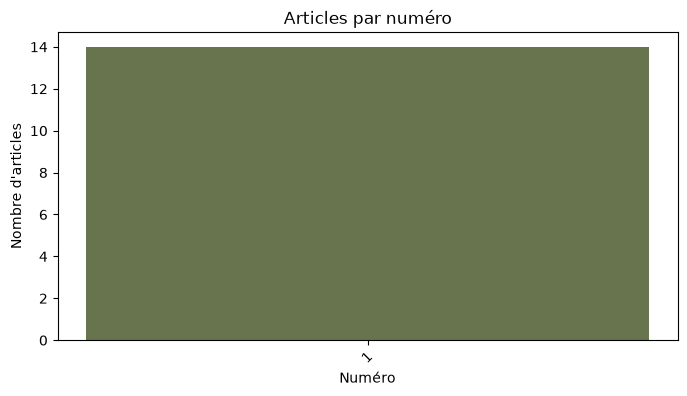

In [108]:
articles_par_numero = df.groupby("numero", as_index=False).agg(
    nb_articles=("ID", "count"),
    numero_num=("numero_num", "first")
)
articles_par_numero = articles_par_numero.sort_values("numero_num").reset_index(drop=True)
display(articles_par_numero)

plt.figure(figsize=(8, 4))
plt.bar(articles_par_numero["numero"], articles_par_numero["nb_articles"], color="#68744D")
plt.xlabel("Numéro")
plt.ylabel("Nombre d'articles")
plt.title("Articles par numéro")
plt.xticks(rotation=45)
plt.savefig(sortie_path / "A01_articles_par_numero_v01.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.4. Voir la taille des textes

La longueur des textes influence les comptages : un long article contient mécaniquement plus d’occurrences. L’histogramme montre si quelques articles très longs risquent de dominer certains résultats.

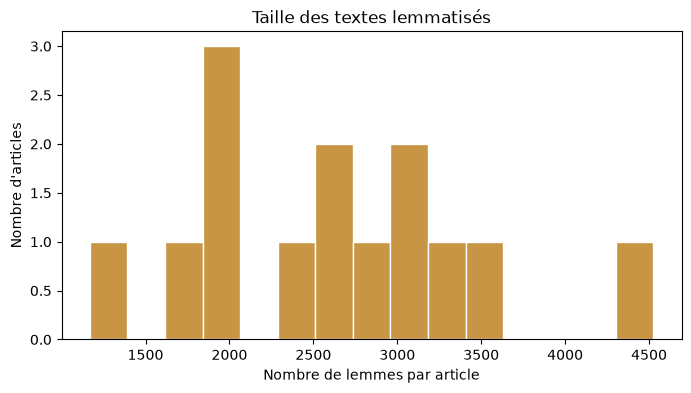

In [109]:
plt.figure(figsize=(8, 4))
plt.hist(df["nb_lemmes"], bins=15, color="#C79543", edgecolor="white")
plt.xlabel("Nombre de lemmes par article")
plt.ylabel("Nombre d'articles")
plt.title("Taille des textes lemmatisés")
plt.savefig(sortie_path / "A01_longueur_articles_v01.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.5. Voir les formes les plus fréquentes

Cette figure sert à contrôler le vocabulaire. Elle ne dit pas ce qui est important : les formes les plus fréquentes peuvent être celles du domaine, de la revue, de la mise en page ou d’une erreur de préparation.

Pour une analyse comparative, regardez aussi, plus bas, les formes présentes dans presque tous les articles.

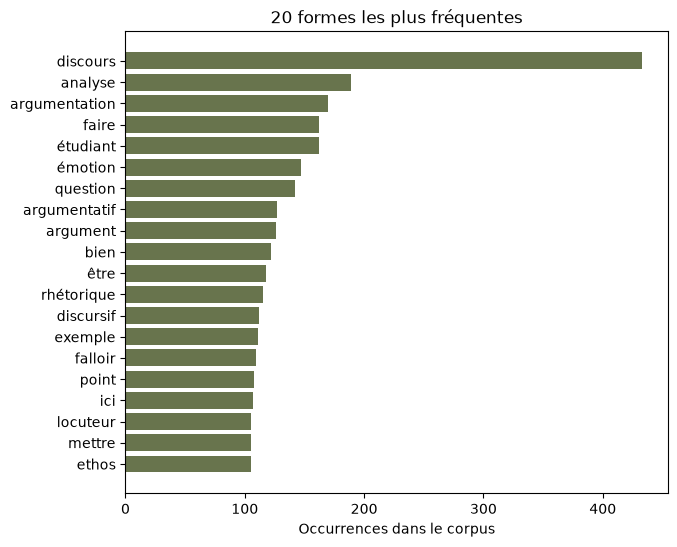

In [110]:
termes_frequents = vocabulaire_df.sort_values("occurrences", ascending=False).head(20)

plt.figure(figsize=(7, 6))
plt.barh(termes_frequents["forme"][::-1], termes_frequents["occurrences"][::-1], color="#68744D")
plt.xlabel("Occurrences dans le corpus")
plt.title("20 formes les plus fréquentes")
plt.savefig(sortie_path / "A01_formes_frequentes_v01.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Préparer la matrice pour l’analyse thématique

Les matrices de la séance 5 contiennent toutes les formes du vocabulaire. Pour chercher des thèmes, nous retirons deux types de formes :
- celles présentes dans trop peu d’articles : elles ne permettent pas de repérer des régularités ;
- celles présentes dans presque tous les articles : elles ne distinguent guère les articles entre eux.

Les deux seuils ci-dessous sont des paramètres d’analyse. Les modifier change les thèmes obtenus : notez toute modification dans votre journal.

Les fichiers de la séance 5 ne sont pas modifiés : nous créons de nouvelles matrices en mémoire, nommées avec le suffixe `_analyse`.

In [111]:
# Paramètres de sélection des formes (à justifier dans votre plan d'analyse)
min_articles = 2             # une forme doit apparaître dans au moins 2 articles
max_proportion_articles = 0.80   # et dans au plus 80 % des articles

n_articles = matrice_comptage.shape[0]

# Pour chaque forme : dans combien d'articles apparaît-elle ?
nb_articles_par_forme = np.asarray((matrice_comptage > 0).sum(axis=0)).ravel()

masque_retenu = (nb_articles_par_forme >= min_articles) & (nb_articles_par_forme <= max_proportion_articles * n_articles)
colonnes_retenues = np.where(masque_retenu)[0]

matrice_comptage_analyse = matrice_comptage[:, colonnes_retenues]
vocabulaire_analyse = vocabulaire[colonnes_retenues]

print("Formes avant sélection :", len(vocabulaire))
print("Formes trop rares :", int((nb_articles_par_forme < min_articles).sum()))
print("Formes trop répandues :", int((nb_articles_par_forme > max_proportion_articles * n_articles).sum()))
print("Formes retenues :", len(vocabulaire_analyse))

# Regarder quelles formes répandues sont retirées.
masque_repandu = nb_articles_par_forme > max_proportion_articles * n_articles
formes_repandues = vocabulaire_df[masque_repandu].sort_values("occurrences", ascending=False)
display(formes_repandues[["forme", "occurrences"]].head(15))

Formes avant sélection : 5968
Formes trop rares : 3350
Formes trop répandues : 103
Formes retenues : 2515


,forme,occurrences
1461,discours,433
278,analyse,189
402,argumentation,170
2126,faire,162
4377,question,142
401,argumentatif,127
397,argument,126
632,bien,122
5963,être,118
4650,rhétorique,115


La liste précédente mérite une lecture critique : les formes retirées sont-elles des termes sans intérêt pour votre question, ou au contraire des termes centraux du domaine ?

Nous recalculons maintenant le TF-IDF sur les formes retenues. Il faut le refaire parce que la pondération et la normalisation de la séance 5 tenaient compte de formes que nous venons de retirer.

In [112]:
ponderation_analyse = TfidfTransformer(norm="l2", smooth_idf=True, sublinear_tf=False)
matrice_tfidf_analyse = ponderation_analyse.fit_transform(matrice_comptage_analyse)

print("Dimensions de la matrice d'analyse :", matrice_tfidf_analyse.shape)

# Articles sans aucune forme retenue : ils n'auront pas de profil thématique.
somme_lignes_analyse = np.asarray(matrice_comptage_analyse.sum(axis=1)).ravel()
print("Articles sans forme retenue :", int((somme_lignes_analyse == 0).sum()))

Dimensions de la matrice d'analyse : (14, 2515)
Articles sans forme retenue : 0


## 4. Chercher des thèmes (A02)

### 4.1. Comprendre la méthode

Nous utilisons une factorisation en matrices non négatives, appelée **NMF**. Elle approxime la matrice TF-IDF par le produit de deux matrices plus petites :

```text
articles × formes  ≈  (articles × thèmes)  ×  (thèmes × formes)
```

- La matrice **thèmes × formes** indique quelles formes caractérisent chaque thème.
- La matrice **articles × thèmes** indique la présence de chaque thème dans chaque article.

Tous les poids sont positifs : un thème s’interprète comme un ensemble de formes qui tendent à apparaître ensemble.

Trois précautions :
- le **nombre de thèmes** est un choix du chercheur, pas une découverte ;
- le programme ne donne pas de titre aux thèmes : les étiquettes viennent de la lecture des formes, des articles représentatifs et des passages ;
- un thème peut regrouper des formes qui coïncident parce qu’elles apparaissent dans quelques articles seulement. Nous contrôlerons cela plus bas.

Cette méthode appartient aux approches exploratoires du README : elle exige un retour aux textes, un examen des paramètres et un contrôle de stabilité.

### 4.2. Calculer les thèmes

`NMF(...)` crée le modèle. `fit_transform(...)` l’ajuste à la matrice et renvoie les poids des thèmes dans chaque article.

Paramètres :
- `nombre_themes` : le nombre de thèmes cherchés. Il doit être inférieur au nombre d’articles. Essayez plusieurs valeurs et comparez ;
- `init="nndsvda"` : un point de départ déterministe, qui donne le même résultat à chaque exécution ;
- `random_state=42` : une graine pour la reproductibilité ;
- `max_iter=500` : le nombre maximal d’itérations.

In [113]:
# Paramètres de l'analyse thématique (à justifier et à noter dans votre plan d'analyse)
nombre_themes = 4
nombre_termes_affiches = 10
graine = 42

if nombre_themes >= n_articles:
    raise ValueError("Choisir un nombre de thèmes inférieur au nombre d'articles.")

modele_themes = NMF(n_components=nombre_themes, init="nndsvda", random_state=graine, max_iter=500)

poids_documents = modele_themes.fit_transform(matrice_tfidf_analyse)   # articles × thèmes
poids_termes = modele_themes.components_                                # thèmes × formes

print("Dimensions articles × thèmes :", poids_documents.shape)
print("Dimensions thèmes × formes :", poids_termes.shape)
print("Itérations utilisées :", modele_themes.n_iter_, "sur", 500)

Dimensions articles × thèmes : (14, 4)
Dimensions thèmes × formes : (4, 2515)
Itérations utilisées : 50 sur 500


Si le nombre d’itérations utilisées est égal au maximum, le modèle n’a peut-être pas convergé : augmentez `max_iter` et reprenez le calcul.

### 4.3. Lire les formes de chaque thème

Pour chaque thème, nous classons les formes selon leur poids et gardons les $N$ premières. La liste `termes_themes` contient une liste de formes par thème ; nous la réutiliserons dans la section 7.

In [114]:
termes_themes = []
lignes_termes = []

for numero_theme in range(nombre_themes):

    poids = poids_termes[numero_theme]
    indices_tries = np.argsort(poids)[::-1][:nombre_termes_affiches]

    termes = []

    for rang, indice in enumerate(indices_tries, start=1):
        termes.append(vocabulaire_analyse[indice])
        lignes_termes.append({
            "theme": numero_theme + 1,
            "rang": rang,
            "forme": vocabulaire_analyse[indice],
            "poids": poids[indice]
        })

    termes_themes.append(termes)
    print("Thème", numero_theme + 1, ":", ", ".join(termes))

table_termes_themes = pd.DataFrame(lignes_termes)
table_termes_themes.to_csv(sortie_path / "A02_termes_par_theme_v01.csv", index=False, encoding="utf-8")

Thème 1 : émotion, sujet, droit, acte, positionnement, raisonnement, problématisation, cause, homme, israélien
Thème 2 : littéraire, ad, discipline, science, littérature, communication, langage, fonctionnement, amossy, entendre
Thème 3 : allemagne, correspondance, guerre, diplomatique, août, étudiant, militaire, image, destinataire, lettre
Thème 4 : performance, médiatique, communicationnel, public, professionnel, interaction, opposition, identité, communication, politicien


### 4.4. Attribuer les thèmes aux articles

Le poids brut d’un thème dépend de la taille du texte et de la normalisation. Pour comparer les articles, nous calculons la **part** de chaque thème dans un article : le poids du thème divisé par la somme des poids de cet article.

Un article reçoit un thème dominant : celui dont la part est la plus élevée. Cette étiquette simplifie ; beaucoup d’articles mêlent plusieurs thèmes.

Un article sans forme retenue a des parts nulles ; il reçoit le thème dominant `0`, pour qu’on le repère.

In [115]:
somme_poids = poids_documents.sum(axis=1)
somme_poids_securisee = np.where(somme_poids == 0, 1, somme_poids)
parts_themes = poids_documents / somme_poids_securisee[:, None]

# Noms provisoires des thèmes : ils seront remplacés après lecture.
noms_themes = []
for numero_theme in range(nombre_themes):
    noms_themes.append("T" + str(numero_theme + 1))

parts_df = pd.DataFrame(parts_themes, columns=noms_themes)
parts_df.insert(0, "ID", df["ID"])

theme_dominant = parts_themes.argmax(axis=1) + 1
theme_dominant = np.where(somme_poids == 0, 0, theme_dominant)

df["theme_dominant"] = theme_dominant
df["part_theme_dominant"] = parts_themes.max(axis=1)

#display(df[["ID", "numero", "annee", "titre", "theme_dominant", "part_theme_dominant"]].head(15))

parts_df.to_csv(sortie_path / "A02_themes_par_article_v01.csv", index=False, encoding="utf-8")

### 4.5. Retourner aux textes : les articles représentatifs

Une liste de formes ne suffit pas pour nommer un thème. Les articles où le thème pèse le plus aident à comprendre de quoi il s’agit. Lisez leurs titres, puis ouvrez au moins un article par thème.

Ici, nous prenons les trois articles où le poids du thème est le plus élevé.

In [116]:
nombre_articles_representatifs = 3

for numero_theme in range(nombre_themes):

    poids_du_theme = poids_documents[:, numero_theme]
    indices_tries = np.argsort(poids_du_theme)[::-1][:nombre_articles_representatifs]

    print("Thème", numero_theme + 1, "—", ", ".join(termes_themes[numero_theme][:6]))

    for indice in indices_tries:
        print("   ", df.at[indice, "ID"], "|", df.at[indice, "numero"], "|", df.at[indice, "titre"][:80])

    print()

Thème 1 — émotion, sujet, droit, acte, positionnement, raisonnement
    aad193 | 1 | L’argumentation dans une problématique d’influence
    aad198 | 1 | Les types d’arguments dans le traitement du débat sur la crise des banlieues par
    aad482 | 1 | L’analyse argumentative en diachronie : le pathos dans les débats parlementaires

Thème 2 — littéraire, ad, discipline, science, littérature, communication
    aad184 | 1 | Introduction
    aad200 | 1 | Argumentation et Analyse du discours : perspectives théoriques et découpages dis
    aad351 | 1 | Analyse du discours et littérature : problèmes épistémologiques et institutionne

Thème 3 — allemagne, correspondance, guerre, diplomatique, août, étudiant
    aad288 | 1 | De la micro-analyse à l’analyse globale des correspondances : lettres de combatt
    aad413 | 1 | Le discours diplomatique dans la correspondance franco-allemande 1871-1914
    aad438 | 1 | Ethos collectif et Rhétorique de polarisation : le discours des étudiants en Fra

Thè

### 4.6. Donner des étiquettes aux thèmes

Après avoir lu les formes, les articles et quelques passages, vous pouvez remplacer les noms provisoires par des étiquettes plus parlantes. Une étiquette est une **interprétation** : justifiez-la dans votre journal et conservez des extraits qui l’appuient.

Dans la cellule suivante, décommentez et modifiez les lignes dont vous êtes sûr. Les noms servent ensuite aux figures et aux tableaux.

In [117]:
# Exemple : remplacer le nom provisoire du thème 1 après lecture des articles.
# noms_themes[0] = "Polémique et controverse"
# noms_themes[1] = "..."

# Reporter les noms dans les tableaux.
parts_df.columns = ["ID"] + noms_themes
display(pd.DataFrame({"theme": range(1, nombre_themes + 1), "nom": noms_themes, "formes": [", ".join(t[:6]) for t in termes_themes]}))

,theme,nom,formes
0,1,T1,"émotion, sujet, droit, acte, positionnement, r..."
1,2,T2,"littéraire, ad, discipline, science, littératu..."
2,3,T3,"allemagne, correspondance, guerre, diplomatiqu..."
3,4,T4,"performance, médiatique, communicationnel, pub..."


### 4.7. Contrôler la répartition et la concentration

Deux questions simples avant d’interpréter :
- combien d’articles ont chaque thème comme thème dominant ?
- quelques articles portent-ils à eux seuls presque tout le poids d’un thème ?

Un thème dont les trois premiers articles contiennent presque tout le poids est peut-être un thème d’un auteur, d’un numéro ou d’un seul texte, plus qu’un thème du corpus.

In [118]:
lignes_controle = []

for numero_theme in range(nombre_themes):

    poids_du_theme = poids_documents[:, numero_theme]
    total_theme = poids_du_theme.sum()

    # Part du poids portée par les trois articles les plus forts.
    trois_premiers = np.sort(poids_du_theme)[::-1][:3].sum()

    if total_theme > 0:
        part_trois_premiers = trois_premiers / total_theme
    else:
        part_trois_premiers = np.nan

    lignes_controle.append({
        "theme": noms_themes[numero_theme],
        "articles_dominants": int((df["theme_dominant"] == numero_theme + 1).sum()),
        "part_du_poids_des_3_premiers_articles": round(part_trois_premiers, 2)
    })

controle_themes = pd.DataFrame(lignes_controle)
display(controle_themes)
controle_themes.to_csv(sortie_path / "A02_controle_concentration_v01.csv", index=False, encoding="utf-8")

,theme,articles_dominants,part_du_poids_des_3_premiers_articles
0,T1,7,0.49
1,T2,3,0.83
2,T3,3,0.86
3,T4,1,0.96


### 4.8. Contrôler la stabilité

Un thème est plus crédible si on le retrouve avec un autre point de départ. Nous relançons le modèle avec trois initialisations aléatoires et, pour chaque thème du premier modèle, nous cherchons le thème le plus proche dans le nouveau modèle, avec la similarité cosinus.

- Une valeur proche de 1 signifie que le thème est retrouvé presque à l’identique.
- Une valeur nettement plus faible indique un thème instable : il dépend du hasard ou du nombre de thèmes choisi.

Ce test ne remplace pas la lecture des textes. Dans un petit corpus, une instabilité est attendue.

In [119]:
graines_test = [11, 22, 33]
stabilite = pd.DataFrame({"theme": noms_themes})

for graine_test in graines_test:

    modele_test = NMF(n_components=nombre_themes, init="random", random_state=graine_test, max_iter=500)
    modele_test.fit(matrice_tfidf_analyse)

    # Similarité entre chaque thème du modèle principal et chaque thème du modèle de test.
    similarites_themes = cosine_similarity(poids_termes, modele_test.components_)
    stabilite["graine_" + str(graine_test)] = similarites_themes.max(axis=1).round(2)

display(stabilite)
stabilite.to_csv(sortie_path / "A02_stabilite_themes_v01.csv", index=False, encoding="utf-8")

c:\Users\franc\My Drive\GitHub\Langues_de_specialite\.venv\Lib\site-packages\sklearn\decomposition\_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 500 reached. Increase it to improve convergence.
  warnings.warn(


,theme,graine_11,graine_22,graine_33
0,T1,0.99,1.0,1.0
1,T2,0.99,1.0,1.0
2,T3,0.97,1.0,1.0
3,T4,0.20,1.0,1.0


## 5. Comparer les thèmes selon une variable (A03)

Une analyse thématique devient plus informative lorsqu’on la relie à une variable : les **auteurs**, le **numéro**, l’**année**. La question change : on ne demande plus seulement « quels thèmes ? », mais « ces thèmes se distribuent-ils de la même façon selon cette variable ? ».

Avant de comparer, rappelons trois précautions du README :
- les groupes ont-ils des tailles comparables ? Une moyenne sur un seul article n’est pas une tendance ;
- un auteur peut avoir écrit pour un seul numéro : auteur et numéro sont alors confondus ;
- un article à plusieurs auteurs compte une fois pour chacun : les groupes ne sont pas indépendants.

Ces comparaisons **décrivent le corpus étudié**. Elles ne permettent pas, à elles seules, d’attribuer un thème à un style d’auteur ou à une évolution de la revue.

### 5.1. Passer d’un article à un couple article–auteur

La colonne `auteurs` contient plusieurs noms séparés par des points-virgules. Pour calculer une moyenne par auteur, nous créons un tableau où chaque ligne est un couple article–auteur : un article à deux auteurs devient deux lignes.

`position` conserve le numéro de ligne de l’article dans le tableau principal, ce qui permet de retrouver ses parts de thèmes.

In [120]:
lignes_auteurs = []

for index, ligne in df.iterrows():

    for auteur in ligne["auteurs"].split(";"):
        auteur = auteur.strip()

        if auteur != "":
            lignes_auteurs.append({"position": index, "ID": ligne["ID"], "auteur": auteur})

articles_auteurs = pd.DataFrame(lignes_auteurs)

print("Couples article–auteur :", len(articles_auteurs))
print("Auteurs distincts :", articles_auteurs["auteur"].nunique())

articles_par_auteur = articles_auteurs.groupby("auteur").size().sort_values(ascending=False)
display(articles_par_auteur.head(10))

Couples article–auteur : 15
Auteurs distincts : 13


auteur
Amossy, Ruth               2
Koren, Roselyne            2
Charaudeau, Patrick        1
Delormas, Pascale          1
Cohen-Wiesenfeld, Sivan    1
Housiel, Sylvie            1
Kalinic, Anne              1
Maingueneau, Dominique     1
Martel, Guylaine           1
Micheli, Raphaël           1
dtype: int64

### 5.2. Calculer la part moyenne de chaque thème par auteur

Pour chaque auteur, nous faisons la moyenne des parts de thèmes de ses articles. Nous gardons aussi le nombre d’articles : c’est le dénominateur qui permet de juger si la moyenne est fiable.

`min_articles_auteur` fixe un effectif minimal. Dans un petit corpus, beaucoup d’auteurs n’ont qu’un article ; les retirer évite de comparer des cas uniques, mais cela réduit la couverture. Si aucun auteur n’atteint le seuil, la cellule le signale et garde tous les auteurs, uniquement pour montrer la procédure.

In [121]:
# Paramètre : effectif minimal d'articles par auteur
min_articles_auteur = 2

tableau_auteurs = articles_auteurs.copy()

for numero_theme in range(nombre_themes):
    tableau_auteurs[noms_themes[numero_theme]] = parts_themes[tableau_auteurs["position"].to_numpy(), numero_theme]

themes_par_auteur = tableau_auteurs.groupby("auteur")[noms_themes].mean()
themes_par_auteur.insert(0, "nb_articles", tableau_auteurs.groupby("auteur").size())

auteurs_retenus = themes_par_auteur[themes_par_auteur["nb_articles"] >= min_articles_auteur]

if len(auteurs_retenus) == 0:
    print("Aucun auteur n'a au moins", min_articles_auteur, "articles : tous les auteurs sont gardés pour la démonstration.")
    auteurs_retenus = themes_par_auteur

auteurs_retenus = auteurs_retenus.sort_values("nb_articles", ascending=False)
display(auteurs_retenus.round(2).head(15))

auteurs_retenus.round(4).to_csv(sortie_path / "A03_themes_par_auteur_v01.csv", encoding="utf-8")

,nb_articles,T1,T2,T3,T4
auteur,,,,,
"Amossy, Ruth",2,0.02,0.90,0.03,0.05
"Koren, Roselyne",2,0.36,0.61,0.00,0.03


### 5.3. Calculer la part moyenne des thèmes par numéro

Le même raisonnement s’applique au numéro. Ici, une ligne du tableau est un article ; nous regroupons par `numero` puis nous trions avec la version numérique.

Pour comparer des **années** plutôt que des numéros, remplacez `"numero"` par `"annee"` dans le `groupby`.

In [122]:
parts_avec_metadonnees = parts_df.copy()
parts_avec_metadonnees["numero"] = df["numero"]
parts_avec_metadonnees["numero_num"] = df["numero_num"]

themes_par_numero = parts_avec_metadonnees.groupby("numero")[noms_themes].mean()
themes_par_numero.insert(0, "nb_articles", parts_avec_metadonnees.groupby("numero").size())
themes_par_numero["numero_num"] = parts_avec_metadonnees.groupby("numero")["numero_num"].first()
themes_par_numero = themes_par_numero.sort_values("numero_num").drop(columns="numero_num")

display(themes_par_numero.round(2))
themes_par_numero.round(4).to_csv(sortie_path / "A03_themes_par_numero_v01.csv", encoding="utf-8")

,nb_articles,T1,T2,T3,T4
numero,,,,,
1,14,0.4,0.26,0.24,0.1


### 5.4. Repérer les formes spécifiques d’un groupe

Les parts de thèmes donnent une vue globale. Pour voir **quels mots** distinguent un groupe, nous calculons une mesure de spécificité (*keyness*) : une statistique du chi² qui compare, pour chaque forme, sa fréquence dans les articles du groupe et dans le reste du corpus.

- Un score **positif** signifie que la forme est plus fréquente que prévu dans le groupe.
- Un score **négatif** signifie qu’elle est moins fréquente.
- La valeur `p` est donnée à titre indicatif. Les mots d’un même article ne sont pas indépendants et nous testons des milliers de formes à la fois : lisez la liste comme une aide à l’exploration, pas comme une preuve.

Nous choisissons d’abord un groupe d’articles. Par défaut : les articles de l’auteur le plus présent. Remplacez la valeur de `auteur_cible` pour en choisir un autre.

In [123]:
# Groupe d'articles à étudier
auteur_cible = articles_par_auteur.index[0]

# Articles écrits par cet auteur (pour un groupe défini autrement, construire un masque différent)
positions_cible = articles_auteurs.loc[articles_auteurs["auteur"] == auteur_cible, "position"].to_numpy()
masque_cible = np.zeros(len(df), dtype=bool)
masque_cible[positions_cible] = True

print("Groupe étudié :", auteur_cible)
print("Articles dans le groupe :", int(masque_cible.sum()))
print("Articles dans le reste du corpus :", int((~masque_cible).sum()))

Groupe étudié : Amossy, Ruth
Articles dans le groupe : 2
Articles dans le reste du corpus : 12


In [124]:
# Paramètre : fréquence minimale totale d'une forme pour être comparée
frequence_minimale = 5

# 1. Compter chaque forme dans le groupe et dans le reste du corpus.
comptes_groupe = np.asarray(matrice_comptage[masque_cible].sum(axis=0)).ravel().astype(float)
comptes_reste = np.asarray(matrice_comptage[~masque_cible].sum(axis=0)).ravel().astype(float)

total_groupe = comptes_groupe.sum()
total_reste = comptes_reste.sum()
total = total_groupe + total_reste

# 2. Calculer le chi² d'un tableau 2 × 2 pour chaque forme :
# (forme / autres formes) × (groupe / reste du corpus).
a = comptes_groupe
b = comptes_reste
numerateur = total * (a * (total_reste - b) - b * (total_groupe - a)) ** 2
denominateur = total_groupe * total_reste * (a + b) * (total - a - b)

chi2_valeurs = np.zeros(len(a))
masque_calcul = (denominateur > 0) & ((a + b) >= frequence_minimale)
chi2_valeurs[masque_calcul] = numerateur[masque_calcul] / denominateur[masque_calcul]

# 3. Donner un signe : positif si la forme est relativement plus fréquente dans le groupe.
signe = np.where(a / total_groupe >= b / total_reste, 1, -1)

specificites = pd.DataFrame({
    "forme": vocabulaire,
    "occurrences_groupe": a.astype(int),
    "occurrences_reste": b.astype(int),
    "chi2": chi2_valeurs * signe,
    "p": loi_chi2.sf(chi2_valeurs, df=1)
})
specificites = specificites[masque_calcul].sort_values("chi2", ascending=False)

print("Formes comparées :", len(specificites))
print("Formes plus fréquentes dans le groupe, avec p < 0,05 :", int(((specificites["chi2"] > 0) & (specificites["p"] < 0.05)).sum()))
display(specificites.head(15).round(3))

Formes comparées : 1600
Formes plus fréquentes dans le groupe, avec p < 0,05 : 192


,forme,occurrences_groupe,occurrences_reste,chi2,p
102,ad,48,12,275.749,0.0
402,argumentation,82,88,225.117,0.0
2234,fonctionnement,25,11,118.281,0.0
1461,discours,121,312,115.384,0.0
261,amossy,22,8,112.234,0.0
401,argumentatif,51,76,102.153,0.0
5933,étude,40,50,95.613,0.0
1459,discipline,32,33,90.546,0.0
278,analyse,63,126,88.303,0.0
4926,science,34,39,87.883,0.0


Les formes les plus spécifiques d’un groupe d’un seul ou de deux articles reflètent surtout le sujet de ces articles. Vérifiez toujours le dénominateur (`total_groupe`) et lisez les passages avant d’interpréter.

Enregistrons le tableau pour le retrouver.

In [125]:
specificites["groupe"] = auteur_cible
specificites.round(4).to_csv(sortie_path / "A03_specificites_groupe_v01.csv", index=False, encoding="utf-8")
print("Tableau enregistré pour le groupe :", auteur_cible)

Tableau enregistré pour le groupe : Amossy, Ruth


## 6. Visualiser les données

Une figure est un **moyen de lire** les tableaux précédents, pas un résultat en soi. Chaque figure répond à une question précise, porte un titre qui nomme l’unité et la mesure, et reste reliée à son tableau d’origine. Nous enregistrons les figures dans le dossier de sortie, avec le même identifiant d’analyse.

### 6.1. Voir les formes qui caractérisent chaque thème

Une rangée de diagrammes en barres : un graphique par thème, les formes avec les poids les plus élevés. Les poids ne sont comparables qu’à l’intérieur d’un thème.

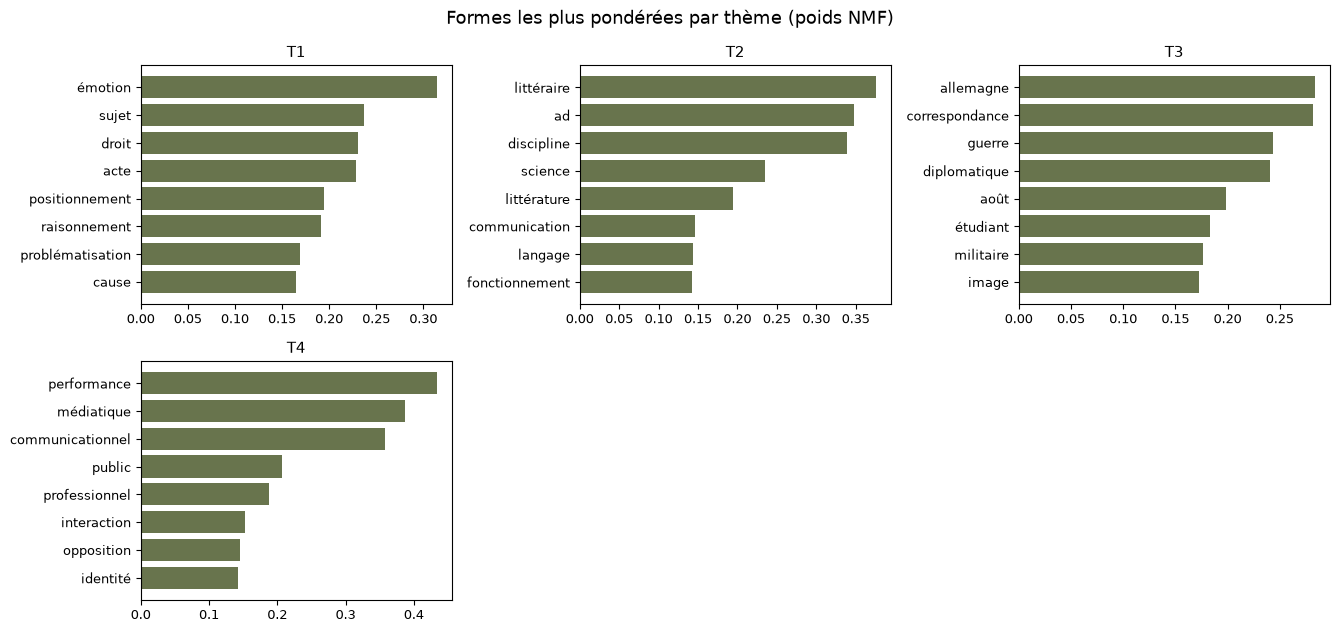

In [126]:
nombre_formes_figure = 8

colonnes_figure = min(nombre_themes, 3)
lignes_figure = int(np.ceil(nombre_themes / colonnes_figure))

fig, axes = plt.subplots(lignes_figure, colonnes_figure, figsize=(4.5 * colonnes_figure, 3.2 * lignes_figure), squeeze=False)

for numero_theme in range(nombre_themes):

    axe = axes[numero_theme // colonnes_figure][numero_theme % colonnes_figure]

    formes = termes_themes[numero_theme][:nombre_formes_figure]
    poids = []

    for forme in formes:
        indice_forme = np.where(vocabulaire_analyse == forme)[0][0]
        poids.append(poids_termes[numero_theme][indice_forme])

    axe.barh(formes[::-1], poids[::-1], color="#68744D")
    axe.set_title(noms_themes[numero_theme], fontsize=11)
    axe.tick_params(labelsize=9)

# Masquer les cases vides.
for case in range(nombre_themes, lignes_figure * colonnes_figure):
    axes[case // colonnes_figure][case % colonnes_figure].axis("off")

fig.suptitle("Formes les plus pondérées par thème (poids NMF)", fontsize=13)
fig.tight_layout()
fig.savefig(sortie_path / "A02_formes_par_theme_v01.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2. Voir la répartition des thèmes dans les articles

Une **carte de chaleur** : une ligne par article, une colonne par thème. Plus la case est foncée, plus la part du thème est grande dans l’article. Les articles sont triés par numéro pour repérer d’éventuels blocs.

Si vous avez beaucoup d’articles, affichez un sous-ensemble ou utilisez les moyennes par numéro (6.3).

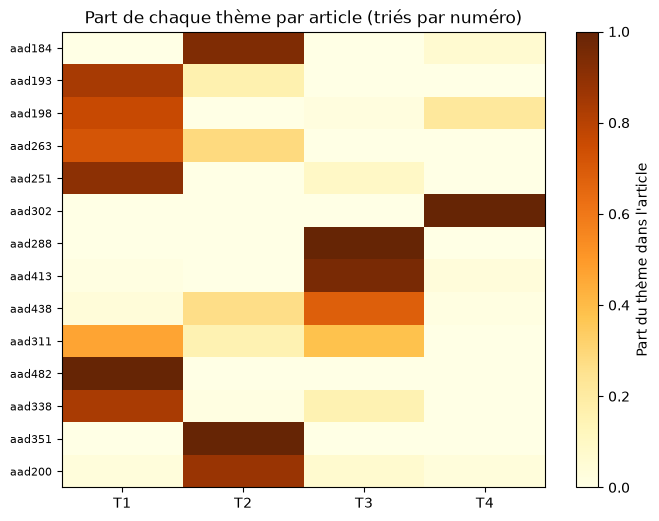

In [127]:
ordre_articles = np.argsort(df["numero_num"].fillna(0).to_numpy(), kind="stable")

plt.figure(figsize=(1.2 * nombre_themes + 3, 0.28 * len(df) + 2))
plt.imshow(parts_themes[ordre_articles], aspect="auto", cmap="YlOrBr", vmin=0, vmax=1)
plt.colorbar(label="Part du thème dans l'article")
plt.xticks(range(nombre_themes), noms_themes)
plt.yticks(range(len(df)), df["ID"].to_numpy()[ordre_articles], fontsize=8)
plt.title("Part de chaque thème par article (triés par numéro)")
plt.savefig(sortie_path / "A02_carte_chaleur_articles_v01.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3. Voir les thèmes par numéro

Un diagramme en barres empilées montre la part moyenne de chaque thème pour chaque numéro. Les parts de chaque barre totalisent 1. Gardez en tête le nombre d’articles : une barre issue de deux articles est beaucoup moins stable qu’une barre issue de vingt articles.

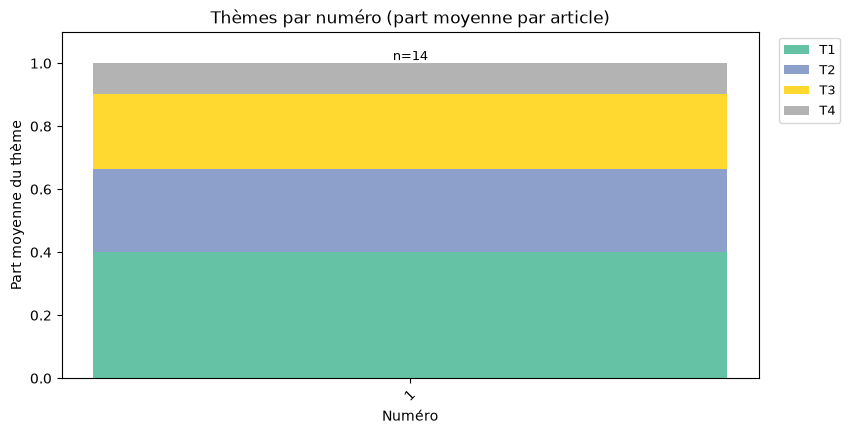

In [128]:
donnees_empilees = themes_par_numero[noms_themes]

fig, axe = plt.subplots(figsize=(9, 4.5))
bas = np.zeros(len(donnees_empilees))
couleurs = plt.cm.Set2(np.linspace(0, 1, nombre_themes))

for numero_theme, nom in enumerate(noms_themes):
    axe.bar(donnees_empilees.index, donnees_empilees[nom], bottom=bas, label=nom, color=couleurs[numero_theme])
    bas = bas + donnees_empilees[nom].to_numpy()

# Écrire le nombre d'articles au-dessus de chaque barre.
for position, nb in enumerate(themes_par_numero["nb_articles"]):
    axe.text(position, 1.01, "n=" + str(int(nb)), ha="center", fontsize=9)

axe.set_xlabel("Numéro")
axe.set_ylabel("Part moyenne du thème")
axe.set_ylim(0, 1.1)
axe.set_title("Thèmes par numéro (part moyenne par article)")
axe.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.xticks(rotation=45)
fig.savefig(sortie_path / "A03_themes_par_numero_v01.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4. Voir les thèmes par auteur

Même figure pour les auteurs retenus en 5.2, sous forme de carte de chaleur. Le nombre d’articles est ajouté dans les étiquettes des lignes.

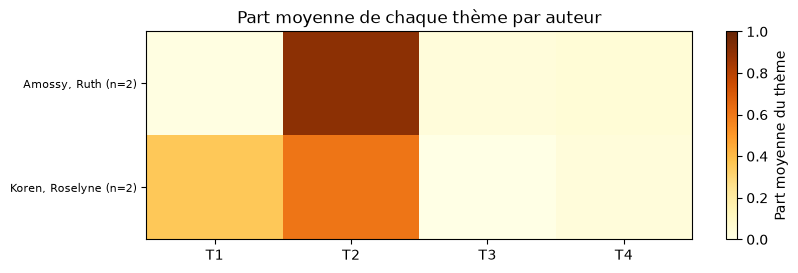

In [129]:
donnees_auteurs = auteurs_retenus.head(15)
etiquettes = []

for auteur, nb in zip(donnees_auteurs.index, donnees_auteurs["nb_articles"]):
    etiquettes.append(auteur + " (n=" + str(int(nb)) + ")")

plt.figure(figsize=(1.2 * nombre_themes + 4, 0.35 * len(donnees_auteurs) + 2))
plt.imshow(donnees_auteurs[noms_themes].to_numpy(), aspect="auto", cmap="YlOrBr", vmin=0, vmax=1)
plt.colorbar(label="Part moyenne du thème")
plt.xticks(range(nombre_themes), noms_themes)
plt.yticks(range(len(donnees_auteurs)), etiquettes, fontsize=8)
plt.title("Part moyenne de chaque thème par auteur")
plt.savefig(sortie_path / "A03_themes_par_auteur_v01.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.5. Projeter les articles en deux dimensions

Une projection place les articles sur un plan pour visualiser leurs ressemblances. Nous utilisons une décomposition en valeurs singulières tronquée (`TruncatedSVD`) de la matrice TF-IDF. Deux articles proches ont des profils lexicaux voisins.

**Attention.** Réduire des milliers de dimensions à deux déforme les distances. Une projection n’est ni une preuve de regroupement, ni une démonstration que deux axes ont un sens. Les couleurs ci-dessous reprennent le thème dominant : si elles se mélangent, ce n’est pas forcément un défaut ; si elles se séparent, ce n’est pas encore une conclusion.

Nous affichons aussi la variance expliquée par chaque axe, pour juger la qualité de la projection.

Variance expliquée par les deux axes : [0.018 0.112]


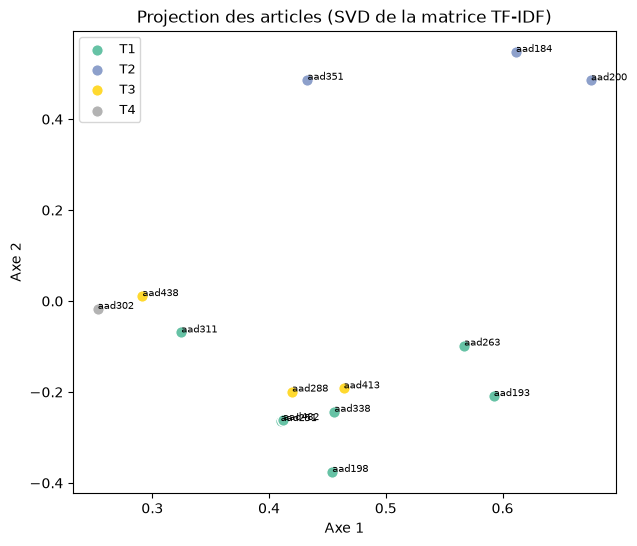

In [130]:
projection = TruncatedSVD(n_components=2, random_state=graine)
coordonnees = projection.fit_transform(matrice_tfidf_analyse)

print("Variance expliquée par les deux axes :", projection.explained_variance_ratio_.round(3))

plt.figure(figsize=(7, 6))
couleurs = plt.cm.Set2(np.linspace(0, 1, nombre_themes))

for numero_theme in range(nombre_themes):
    masque = df["theme_dominant"].to_numpy() == numero_theme + 1
    plt.scatter(coordonnees[masque, 0], coordonnees[masque, 1], color=couleurs[numero_theme], s=70, label=noms_themes[numero_theme], edgecolor="white")

# Étiqueter quelques points pour retrouver les articles.
for position in range(len(df)):
    plt.text(coordonnees[position, 0], coordonnees[position, 1], df.at[position, "ID"], fontsize=7)

plt.xlabel("Axe 1")
plt.ylabel("Axe 2")
plt.title("Projection des articles (SVD de la matrice TF-IDF)")
plt.legend(fontsize=9)
plt.savefig(sortie_path / "A02_projection_articles_v01.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.6. Voir un article en détail

Le retour au texte reste la meilleure visualisation. Pour un article, nous affichons son profil de thèmes, puis les formes de la matrice qui pèsent le plus dans son TF-IDF. Choisissez l’article avec `index_exemple`.

In [131]:
index_exemple = 0

print("Article :", df.at[index_exemple, "ID"], "|", df.at[index_exemple, "titre"])
print("Auteurs :", df.at[index_exemple, "auteurs"])
print()

print("Parts de thèmes :")
for numero_theme in range(nombre_themes):
    print("  ", noms_themes[numero_theme], ":", round(parts_themes[index_exemple, numero_theme], 2))

# Les dix formes les plus pondérées de cet article dans la matrice TF-IDF d'analyse.
ligne_tfidf = matrice_tfidf_analyse[index_exemple].toarray().ravel()
indices_formes = np.argsort(ligne_tfidf)[::-1][:10]

print()
print("Formes les plus pondérées :")
for indice in indices_formes:
    print("  ", vocabulaire_analyse[indice], round(ligne_tfidf[indice], 3))

Article : aad184 | Introduction
Auteurs : Amossy, Ruth; Koren, Roselyne

Parts de thèmes :
   T1 : 0.0
   T2 : 0.94
   T3 : 0.0
   T4 : 0.06

Formes les plus pondérées :
   ad 0.406
   discipline 0.251
   numéro 0.182
   corpus 0.167
   entendre 0.145
   fonctionnement 0.133
   champ 0.126
   science 0.124
   langage 0.116
   littéraire 0.114


## 7. Rechercher de l’information (A04)

La **recherche d’information** consiste à retrouver, dans un corpus, les documents pertinents pour une requête. Elle suit une progression du plus simple au plus riche :

| Modèle | Idée | Limite |
|---|---|---|
| Booléen sur le texte (regex) | Le document contient ou non le motif | Motifs lourds à écrire ; aucune mesure de pertinence |
| Booléen sur les lemmes | Idem, mais indépendant de la flexion | Toujours aucune pertinence graduée |
| Matrice binaire | Présence ou absence de chaque forme | Dépend du vocabulaire de la matrice |
| Vecteur-requête et cosinus | Les documents sont classés par similarité | Dépend de la pondération et du vocabulaire |
| Requête consolidée | On ajoute des formes spécifiques aux meilleurs résultats | Risque de dérive de la requête |

Dans cette section, nous utilisons les matrices **complètes** de la séance 5 (`matrice_comptage` et `matrice_tfidf`), pas celles filtrées pour les thèmes. Une forme absente du vocabulaire ne peut pas servir de requête.

Cette section s'inspire de *J5_recherche_information* (D. Pulizzotto, 2020).

### 7.1. Définir la requête

Une requête est une liste de mots. Comme les matrices contiennent des **lemmes**, il faut écrire les mots de la requête sous leur forme de lemme.

Nous écrivons les mots tels que nous les pensons ; spaCy en donne ensuite le lemme, et nous vérifions que chaque lemme figure dans le vocabulaire. Les mots de l’exemple sont à remplacer par des mots de votre propre corpus : s’ils sont absents, la cellule vous le dira.

Si un mot est composé, regardez comment spaCy le découpe avant de l’utiliser.

In [132]:
# Mots de la requête, écrits comme dans un texte (à remplacer par des mots de votre corpus)
mots_requete_texte = ["émotion", "sentiment"]

# 1. Obtenir le lemme de chaque mot avec spaCy.
lemmes_requete = []

for mot in mots_requete_texte:
    for token in nlp(mot):
        lemme = token.lemma_.lower().strip()

        if lemme != "" and lemme not in lemmes_requete:
            lemmes_requete.append(lemme)

print("Lemmes de la requête :", lemmes_requete)

# 2. Vérifier que ces lemmes appartiennent au vocabulaire de la matrice.
indices_vocabulaire = {}
for position, forme in enumerate(vocabulaire):
    indices_vocabulaire[forme] = position

lemmes_dans_vocabulaire = []
lemmes_absents = []

for lemme in lemmes_requete:
    if lemme in indices_vocabulaire:
        lemmes_dans_vocabulaire.append(lemme)
    else:
        lemmes_absents.append(lemme)

print("Présents dans le vocabulaire :", lemmes_dans_vocabulaire)
print("Absents du vocabulaire :", lemmes_absents)

if len(lemmes_dans_vocabulaire) == 0:
    raise ValueError("Aucun mot de la requête n'est dans le vocabulaire : choisir d'autres mots.")

Lemmes de la requête : ['émotion', 'sentiment']
Présents dans le vocabulaire : ['émotion', 'sentiment']
Absents du vocabulaire : []


### 7.2. Modèle booléen : chercher un motif dans le texte

Une expression régulière sert de requête. Un article est pertinent s’il contient le motif ; il n’y a pas de degré de pertinence.

`str.contains(motif, case=False, regex=True)` renvoie `True` ou `False` pour chaque article. `case=False` ignore la casse : *Polémique* et *polémique* sont trouvés ensemble.

Trois variantes à comparer :
- un seul mot ;
- **ou** : l’un des mots (`mot1|mot2`) ;
- **et** : tous les mots (`(?=.*mot1)(?=.*mot2)`), où chaque `(?=.*mot)` vérifie que le mot apparaît quelque part dans le texte. Dans `.*`, le `.` signifie « n'importe quel caractère » et `*` signifie « zéro ou plusieurs fois ». Par défaut, `.` ne reconnaît pas les sauts de ligne. Le préfixe `(?s)` change ce comportement pour que `.` puisse aussi les reconnaître, ce qui permet de chercher un mot dans l'ensemble d'un texte comportant plusieurs lignes.

Les mots utilisés ici sont les mots de la requête tels qu’écrits. Une forme fléchie (*sentiments*) est trouvée seulement si le motif la contient.

In [133]:
texte_nettoye_serie = df["texte_nettoye"]

# 1. Un seul mot
for mot in mots_requete_texte:
    masque = texte_nettoye_serie.str.contains(mot, case=False, regex=True)
    print("Articles contenant", repr(mot), ":", int(masque.sum()))

# 2. L'un des mots (ou)
motif_ou = "|".join(re.escape(mot) for mot in mots_requete_texte)
masque_ou = texte_nettoye_serie.str.contains(motif_ou, case=False, regex=True)
print("Articles contenant l'un des mots :", int(masque_ou.sum()))

# 3. Tous les mots (et) : une assertion « lookahead » par mot
motif_et = "(?s)" + "".join("(?=.*" + re.escape(mot) + ")" for mot in mots_requete_texte)
masque_et = texte_nettoye_serie.str.contains(motif_et, case=False, regex=True)
print("Articles contenant tous les mots :", int(masque_et.sum()))

Articles contenant 'émotion' : 10
Articles contenant 'sentiment' : 9
Articles contenant l'un des mots : 11
Articles contenant tous les mots : 8


Regardons les résultats **dans leur contexte**. Pour chaque article trouvé, nous extrayons jusqu’à deux passages : 50 caractères avant et après le motif. `re.finditer` parcourt toutes les occurrences ; `match.start()` et `match.end()` donnent leurs positions.

In [134]:
positions_ou = np.where(masque_ou)[0]
nombre_articles_apercu = 5

for position in positions_ou[:nombre_articles_apercu]:

    texte = df.at[position, "texte_nettoye"]
    print(df.at[position, "ID"], "|", df.at[position, "titre"][:70])

    nombre_passages = 0

    for occurrence in re.finditer(motif_ou, texte, flags=re.IGNORECASE):

        debut = max(0, occurrence.start() - 50)
        fin = min(len(texte), occurrence.end() + 50)
        passage = texte[debut:fin].replace("\n", " ")
        print("    …" + passage + "…")

        nombre_passages = nombre_passages + 1
        if nombre_passages == 2:
            break

    print()

aad193 | L’argumentation dans une problématique d’influence
    …e pathos de la rhétorique qui, s'appuyant sur les émotions susceptibles de faire se mouvoir l'individu dans…
    …érable, l'efficace/l'inefficace ; hédonique : les sentiments, l'émotionnel, le sensible, le désirable, la men…

aad198 | Les types d’arguments dans le traitement du débat sur la crise des ban
    …nt de crispations sociales prêtant à alimenter un sentiment d'injustice et peut-être aussi une certaine agres…
    …cutrice confirme cette situation d'obligation d'assentiment, bien qu'elle rectifie sa position par la suite e…

aad263 | Pour une éthique du discours : prise de position et rationalité axiolo
    …ouve de nombreuses qualifications axiologiques ou émotionnelles comme « désordre », « pénurie », « villes d…

aad302 | Performance… et contre-performance communicationnelles : des stratégie
    … calme, plus conciliant, mieux en contrôle de ses émotions.  Mais la manœuvre n'est pas sans risque : à for…

aad288

Cette méthode a deux limites :
1. **Les motifs deviennent compliqués** : féminin et masculin, singulier et pluriel, variantes d’orthographe.
2. **Tous les documents trouvés ont la même valeur** : aucun classement, aucune mesure de pertinence.

### 7.3. Modèle booléen sur les lemmes

Pour résoudre le premier problème, nous interrogeons le texte **lemmatisé** de la séance 5. Les mots y sont déjà ramenés à leur lemme ; une requête sur `sentiment` trouve aussi `sentiments`.

Nous transformons le texte de chaque article en **ensemble** de lemmes (`set`) : demander si un lemme appartient à un ensemble est rapide et se lit simplement.

Le modèle reste booléen : un article contient le lemme ou non. Et il dépend du texte lemmatisé de la séance 5, donc des mots-outils retirés.

In [135]:
ensembles_lemmes = []

for texte_lemmatise in df["texte_lemmatise"]:
    ensembles_lemmes.append(set(texte_lemmatise.split()))

# 1. Un seul lemme
for lemme in lemmes_dans_vocabulaire:
    positions_lemme = [i for i, ensemble in enumerate(ensembles_lemmes) if lemme in ensemble]
    print("Articles contenant le lemme", repr(lemme), ":", len(positions_lemme))

# 2. L'un des lemmes (ou)
positions_lemmes_ou = [i for i, ensemble in enumerate(ensembles_lemmes) if any(l in ensemble for l in lemmes_dans_vocabulaire)]
print("Articles contenant l'un des lemmes :", len(positions_lemmes_ou))

# 3. Tous les lemmes (et)
positions_lemmes_et = [i for i, ensemble in enumerate(ensembles_lemmes) if all(l in ensemble for l in lemmes_dans_vocabulaire)]
print("Articles contenant tous les lemmes :", len(positions_lemmes_et))

Articles contenant le lemme 'émotion' : 6
Articles contenant le lemme 'sentiment' : 9
Articles contenant l'un des lemmes : 10
Articles contenant tous les lemmes : 5


### 7.4. Passer à la matrice binaire

Le modèle vectoriel commence par une matrice **binaire** : une cellule vaut `True` si la forme est présente dans l’article, `False` sinon. Elle donne les mêmes réponses que la requête sur les lemmes, avec une écriture plus courte.

`matrice_comptage > 0` produit cette matrice en une opération. Pour interroger un lemme, nous prenons la colonne qui lui correspond dans le vocabulaire.

**Attention.** Si la séance 5 avait retiré des formes rares, ces formes ne seraient pas dans la matrice et ne pourraient pas servir de requête. Dans cet exemple, la matrice n’est pas filtrée.

In [136]:
matrice_binaire = (matrice_comptage > 0).tocsr()

positions_binaire_ou = set()

for lemme in lemmes_dans_vocabulaire:
    colonne = indices_vocabulaire[lemme]
    articles_du_lemme = matrice_binaire[:, colonne].nonzero()[0]
    print("Articles contenant", repr(lemme), "dans la matrice binaire :", len(articles_du_lemme))
    positions_binaire_ou.update(articles_du_lemme)

print("Articles contenant l'un des lemmes (matrice binaire) :", len(positions_binaire_ou))
print("Même résultat que la requête sur les lemmes ?", positions_binaire_ou == set(positions_lemmes_ou))

Articles contenant 'émotion' dans la matrice binaire : 6
Articles contenant 'sentiment' dans la matrice binaire : 9
Articles contenant l'un des lemmes (matrice binaire) : 10
Même résultat que la requête sur les lemmes ? True


Si la dernière ligne affiche `False`, cherchez d’où vient la différence : mot d’une seule lettre ignoré par le comptage, formes retirées de la matrice, ou lemmes différents. Une différence n’est pas forcément une erreur ; elle doit pouvoir s’expliquer.

### 7.5. Construire le vecteur-requête

Pour obtenir un **degré de pertinence**, il faut une mesure de similarité entre la requête et chaque article. Nous représentons donc la requête dans le **même espace** que les articles : un vecteur de la longueur du vocabulaire, avec 0 partout, sauf `1` aux colonnes des lemmes de la requête.

`sparse.lil_matrix` crée une matrice creuse que l’on peut remplir cellule par cellule.

In [137]:
nombre_formes = matrice_tfidf.shape[1]

# 1. Créer un vecteur vide (une ligne, autant de colonnes que de formes).
vecteur_requete = sparse.lil_matrix((1, nombre_formes))

# 2. Mettre 1 aux colonnes des lemmes de la requête.
for lemme in lemmes_dans_vocabulaire:
    vecteur_requete[0, indices_vocabulaire[lemme]] = 1

vecteur_requete = vecteur_requete.tocsr()

# 3. Contrôler : quelles colonnes contiennent 1 ?
colonnes_non_nulles = vecteur_requete.nonzero()[1]
print("Formes du vecteur-requête :", [vocabulaire[c] for c in colonnes_non_nulles])
print("Valeurs :", vecteur_requete.data)

Formes du vecteur-requête : ['sentiment', 'émotion']
Valeurs : [1. 1.]


### 7.6. Calculer la similarité et classer les articles

Nous comparons le vecteur-requête à **chaque ligne de la matrice TF-IDF** avec la **similarité cosinus** : le cosinus de l’angle entre deux vecteurs. Elle vaut 0 si les vecteurs n’ont aucune forme commune et se rapproche de 1 quand ils pointent dans la même direction.

Pourquoi le TF-IDF plutôt que le comptage ? Une forme rare dans le corpus et fréquente dans un article pèse plus lourd que des formes banales. L’article est donc mieux placé s’il traite surtout de la requête.

Le résultat est un tableau : un article par ligne, avec son cosinus. Nous le classons, puis nous regardons la distribution pour choisir un seuil.

In [138]:
similarites = cosine_similarity(matrice_tfidf, vecteur_requete).ravel()

resultats_requete = pd.DataFrame({
    "ID": df["ID"],
    "numero": df["numero"],
    "titre": df["titre"],
    "cosinus": similarites
})
resultats_requete = resultats_requete.sort_values("cosinus", ascending=False).reset_index(drop=True)

print("Articles avec un cosinus supérieur à 0 :", int((similarites > 0).sum()))
print()
display(resultats_requete.head(10).round(3))

Articles avec un cosinus supérieur à 0 : 10



,ID,numero,titre,cosinus
0,aad482,1,L’analyse argumentative en diachronie : le pat...,0.419
1,aad338,1,Pratiques discursives et enjeux du pathos dans...,0.084
2,aad200,1,Argumentation et Analyse du discours : perspec...,0.026
3,aad413,1,Le discours diplomatique dans la correspondanc...,0.025
4,aad288,1,De la micro-analyse à l’analyse globale des co...,0.021
5,aad193,1,L’argumentation dans une problématique d’influ...,0.016
6,aad198,1,Les types d’arguments dans le traitement du dé...,0.010
7,aad311,1,L’image de soi dans les « autographies » de Ro...,0.005
8,aad302,1,Performance… et contre-performance communicati...,0.004
9,aad438,1,Ethos collectif et Rhétorique de polarisation ...,0.002


### 7.7. Choisir un seuil et explorer la distribution

Deux façons de sélectionner les articles pertinents :
- un **seuil de similarité** : tous les articles dont le cosinus dépasse une valeur ;
- les **n meilleurs** : les n premiers du classement.

Il n’existe pas de seuil universel. Le seuil dépend du corpus, du nombre de mots de la requête et de la pondération. Regardez d’abord la distribution des valeurs non nulles : un seuil placé dans un creux sépare mieux que le seuil 0,2 de l’exemple. Notez le seuil retenu et sa justification.

count    10.000
mean      0.061
std       0.128
min       0.002
25%       0.007
50%       0.019
75%       0.026
max       0.419
Name: cosinus, dtype: float64


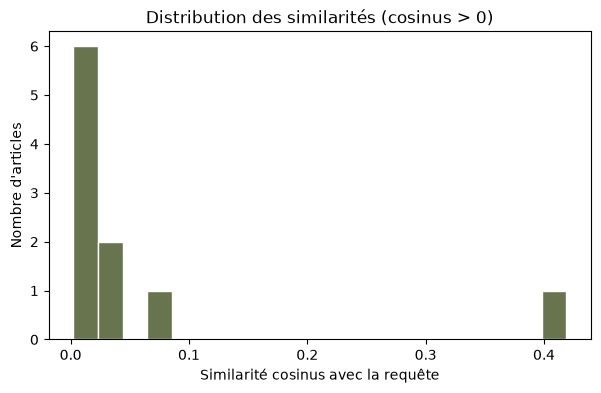

In [139]:
valeurs_non_nulles = resultats_requete.loc[resultats_requete["cosinus"] > 0, "cosinus"]
print(valeurs_non_nulles.describe().round(3))

plt.figure(figsize=(7, 4))
plt.hist(valeurs_non_nulles, bins=20, color="#68744D", edgecolor="white")
plt.xlabel("Similarité cosinus avec la requête")
plt.ylabel("Nombre d'articles")
plt.title("Distribution des similarités (cosinus > 0)")
plt.savefig(sortie_path / "A04_distribution_similarites_v01.png", dpi=150, bbox_inches="tight")
plt.show()

In [140]:
# Paramètres : seuil de similarité ou nombre d'articles à garder
seuil_similarite = 0.10
nombre_meilleurs = 4

articles_au_dessus_du_seuil = resultats_requete[resultats_requete["cosinus"] > seuil_similarite]
meilleurs_articles = resultats_requete.head(nombre_meilleurs)

print("Articles au-dessus du seuil", seuil_similarite, ":", len(articles_au_dessus_du_seuil))
display(meilleurs_articles.round(3))

ids_pertinents = meilleurs_articles["ID"].tolist()

Articles au-dessus du seuil 0.1 : 1


,ID,numero,titre,cosinus
0,aad482,1,L’analyse argumentative en diachronie : le pat...,0.419
1,aad338,1,Pratiques discursives et enjeux du pathos dans...,0.084
2,aad200,1,Argumentation et Analyse du discours : perspec...,0.026
3,aad413,1,Le discours diplomatique dans la correspondanc...,0.025


### 7.8. Consolider la requête avec les formes spécifiques

Une requête de deux mots est pauvre. Pour l’enrichir, nous cherchons les **formes spécifiques** des meilleurs articles par rapport au reste du corpus (même calcul qu’en 5.4), puis nous les ajoutons à la requête.

**Risque de dérive.** Les formes spécifiques d’un petit nombre d’articles reflètent aussi le sujet particulier de ces articles. Ajoutées à la requête, elles peuvent éloigner la recherche de la question initiale. Lisez la liste avant de l’intégrer.

Pour cette démonstration, nous prenons les articles de `meilleurs_articles`, avec une fréquence minimale de 3.

In [141]:
# Groupe : les meilleurs articles de la requête
positions_pertinentes = df.index[df["ID"].isin(ids_pertinents)].to_numpy()
masque_pertinent = np.zeros(len(df), dtype=bool)
masque_pertinent[positions_pertinentes] = True

frequence_minimale_requete = 3
nombre_formes_ajoutees = 5

# Comptes dans le groupe et dans le reste du corpus (matrice complète)
a = np.asarray(matrice_comptage[masque_pertinent].sum(axis=0)).ravel().astype(float)
b = np.asarray(matrice_comptage[~masque_pertinent].sum(axis=0)).ravel().astype(float)
total_groupe = a.sum()
total_reste = b.sum()
total = total_groupe + total_reste

numerateur = total * (a * (total_reste - b) - b * (total_groupe - a)) ** 2
denominateur = total_groupe * total_reste * (a + b) * (total - a - b)

chi2_valeurs = np.zeros(len(a))
masque_calcul = (denominateur > 0) & ((a + b) >= frequence_minimale_requete)
chi2_valeurs[masque_calcul] = numerateur[masque_calcul] / denominateur[masque_calcul]

signe = np.where(a / total_groupe >= b / total_reste, 1, -1)

specificites_requete = pd.DataFrame({
    "forme": vocabulaire,
    "occurrences_groupe": a.astype(int),
    "occurrences_reste": b.astype(int),
    "chi2": chi2_valeurs * signe,
    "p": loi_chi2.sf(chi2_valeurs, df=1)
})
specificites_requete = specificites_requete[masque_calcul].sort_values("chi2", ascending=False)

# Formes candidates : plus fréquentes dans le groupe, avec p < 0,05, hors mots déjà dans la requête.
candidates = specificites_requete[(specificites_requete["chi2"] > 0) & (specificites_requete["p"] < 0.05)]
candidates = candidates[~candidates["forme"].isin(lemmes_dans_vocabulaire)]

display(candidates.head(15).round(3))
formes_ajoutees = candidates["forme"].head(nombre_formes_ajoutees).tolist()
print("Formes proposées pour la requête :", formes_ajoutees)

,forme,occurrences_groupe,occurrences_reste,chi2,p
1447,diplomatique,40,2,61.714,0.0
2104,exécution,38,1,61.693,0.0
2951,israélien,37,1,59.975,0.0
3413,mort,46,7,57.007,0.0
5103,spectateur,30,0,51.542,0.0
3835,pathos,35,5,44.235,0.0
3744,palestinien,25,0,42.946,0.0
3947,pitié,24,0,41.227,0.0
3860,peine,31,4,40.354,0.0
5401,topique,34,7,37.530,0.0


Formes proposées pour la requête : ['diplomatique', 'exécution', 'israélien', 'mort', 'spectateur']


Après lecture, on peut retirer une forme jugée hors sujet : modifiez simplement la liste `formes_ajoutees`. Nous reconstruisons ensuite le vecteur-requête et relançons la recherche exactement comme en 7.5 et 7.6.

In [142]:
formes_ajoutees = ["émotionnel", "pathos"]
lemmes_requete_consolidee = lemmes_dans_vocabulaire + [f for f in formes_ajoutees if f not in lemmes_dans_vocabulaire]

vecteur_requete_2 = sparse.lil_matrix((1, nombre_formes))

for lemme in lemmes_requete_consolidee:
    vecteur_requete_2[0, indices_vocabulaire[lemme]] = 1

vecteur_requete_2 = vecteur_requete_2.tocsr()

similarites_2 = cosine_similarity(matrice_tfidf, vecteur_requete_2).ravel()

resultats_requete_2 = pd.DataFrame({
    "ID": df["ID"],
    "numero": df["numero"],
    "titre": df["titre"],
    "cosinus": similarites_2
})
resultats_requete_2 = resultats_requete_2.sort_values("cosinus", ascending=False).reset_index(drop=True)

print("Requête consolidée :", lemmes_requete_consolidee)
display(resultats_requete_2.head(10).round(3))

# Comparer les cinq meilleurs articles avant et après consolidation.
ids_avant = set(resultats_requete.head(nombre_meilleurs)["ID"])
ids_apres = set(resultats_requete_2.head(nombre_meilleurs)["ID"])
print("Articles communs aux deux classements :", len(ids_avant & ids_apres), "sur", nombre_meilleurs)

Requête consolidée : ['émotion', 'sentiment', 'émotionnel', 'pathos']


,ID,numero,titre,cosinus
0,aad482,1,L’analyse argumentative en diachronie : le pat...,0.352
1,aad338,1,Pratiques discursives et enjeux du pathos dans...,0.148
2,aad200,1,Argumentation et Analyse du discours : perspec...,0.042
3,aad193,1,L’argumentation dans une problématique d’influ...,0.024
4,aad288,1,De la micro-analyse à l’analyse globale des co...,0.022
5,aad413,1,Le discours diplomatique dans la correspondanc...,0.021
6,aad184,1,Introduction,0.016
7,aad198,1,Les types d’arguments dans le traitement du dé...,0.011
8,aad311,1,L’image de soi dans les « autographies » de Ro...,0.008
9,aad302,1,Performance… et contre-performance communicati...,0.003


Articles communs aux deux classements : 3 sur 4


### 7.9. Chercher les articles les plus proches d’un ou de plusieurs articles

Une requête n’est pas toujours une liste de mots. On peut chercher les articles **les plus proches d’un article, ou d’un groupe d’articles**. Le vecteur-requête est alors la **moyenne** des lignes de la matrice pour ces articles. Nous utilisons les comptages pour construire le vecteur et le TF-IDF pour le comparer.

Limite de la moyenne : elle écrase les différences entre les articles du groupe et se laisse tirer par les plus longs.

Ici, nous prenons comme modèle les articles de `ids_pertinents`.

In [143]:
# Moyenne des lignes de comptage des articles pertinents
moyenne_groupe = np.asarray(matrice_comptage[positions_pertinentes].mean(axis=0))
vecteur_requete_3 = sparse.csr_matrix(moyenne_groupe)

similarites_3 = cosine_similarity(matrice_tfidf, vecteur_requete_3).ravel()

resultats_requete_3 = pd.DataFrame({
    "ID": df["ID"],
    "numero": df["numero"],
    "titre": df["titre"],
    "cosinus": similarites_3
})
resultats_requete_3 = resultats_requete_3.sort_values("cosinus", ascending=False).reset_index(drop=True)

# Marquer les articles qui ont servi de modèle : ils sont naturellement proches.
resultats_requete_3["article_modele"] = resultats_requete_3["ID"].isin(ids_pertinents)

display(resultats_requete_3.head(10).round(3))

,ID,numero,titre,cosinus,article_modele
0,aad200,1,Argumentation et Analyse du discours : perspec...,0.702,True
1,aad482,1,L’analyse argumentative en diachronie : le pat...,0.670,True
2,aad184,1,Introduction,0.549,False
3,aad338,1,Pratiques discursives et enjeux du pathos dans...,0.514,True
4,aad413,1,Le discours diplomatique dans la correspondanc...,0.501,True
5,aad263,1,Pour une éthique du discours : prise de positi...,0.462,False
6,aad193,1,L’argumentation dans une problématique d’influ...,0.431,False
7,aad351,1,Analyse du discours et littérature : problèmes...,0.368,False
8,aad198,1,Les types d’arguments dans le traitement du dé...,0.350,False
9,aad251,1,Pertinence de l’utilisation du modèle de Toulm...,0.318,False


Les articles modèles se retrouvent en tête, ce qui est normal. L’intérêt est dans les autres articles proches : ceux que la requête par mots n’avait pas trouvés.

### 7.10. Retourner au texte : concordances et mise en évidence

Un classement n’est pas un résultat tant que les passages n’ont pas été lus. Nous construisons une **concordance** : pour chaque occurrence d’un mot de la requête, le contexte à gauche et à droite.

Comme les mots de la requête sont des lemmes, nous les retrouvons dans le texte avec spaCy : un mot est retenu si son **lemme** correspond à l’un des lemmes de la requête. Cela trouve *polémique* et *polémiques* ensemble.

Pour limiter le temps de calcul, nous traitons seulement les articles les mieux classés (`ids_pertinents`).

In [144]:
largeur_contexte = 60
lignes_concordance = []

for identifiant in ids_pertinents:

    position = int(df.index[df["ID"] == identifiant][0])
    texte = df.at[position, "texte_nettoye"]

    document = nlp(texte)

    for token in document:

        if token.lemma_.lower() in lemmes_requete_consolidee:

            gauche = texte[max(0, token.idx - largeur_contexte):token.idx].replace("\n", " ")
            droite = texte[token.idx + len(token.text):token.idx + len(token.text) + largeur_contexte].replace("\n", " ")

            lignes_concordance.append({
                "ID": identifiant,
                "contexte_gauche": gauche,
                "forme": token.text,
                "lemme": token.lemma_.lower(),
                "contexte_droit": droite
            })

concordance = pd.DataFrame(lignes_concordance)

print("Occurrences trouvées :", len(concordance))
display(concordance.head(15))

Occurrences trouvées : 230


,ID,contexte_gauche,forme,lemme,contexte_droit
0,aad482,erche en cours qui porte sur la construction d...,émotions,émotion,dans un corpus de débats parlementaires franç...
1,aad482,"uinzaine d'années, à un « retour » de la probl...",émotion,émotion,au sein de la théorie de l'argumentation et d...
2,aad482,uteurs se réclamant d'une approche normative d...,émotion,émotion,et ceux qui revendiquent une approche plus de...
3,aad482,tifier les critères permettant de départager l...,émotion,émotion,« rationnels » des appels à l'émotion « falla...
4,aad482,rtager les appels à l'émotion « rationnels » d...,émotion,émotion,"« fallacieux ». On citera, à ce titre, les tr..."
5,aad482,éorie résolument pragmatique des fallacies : l...,émotion,émotion,n'y font pas l'objet d'une ontologisation nég...
6,aad482,ait être et ne cherchent pas à évaluer en quoi...,émotion,émotion,peut entraver la « bonne » tenue du processus...
7,aad482,décrire comment les discours argumentatifs con...,émotions,émotion,: on citera les travaux de Christian Plantin ...
8,aad482,lopper les enjeux de ce « retour » de la probl...,émotion,émotion,"au sein de la théorie de l'argumentation, ni ..."
9,aad482,rire avec le plus de rigueur possible la const...,émotion,émotion,"dans et par le discours. C'est donc, méthodol..."


Une concordance se **trie** pour faire apparaître des régularités : par exemple selon le mot qui suit ou qui précède. Regardez aussi quels articles dominent la liste : un seul article très long peut fournir la plupart des lignes.

In [145]:
if len(concordance) > 0:
    print("Occurrences par article :")
    display(concordance["ID"].value_counts())

    print("Occurrences par lemme :")
    display(concordance["lemme"].value_counts())

    # Trier selon le contexte droit pour repérer les suites fréquentes.
    display(concordance.sort_values("contexte_droit").head(10))

Occurrences par article :


ID
aad482    167
aad338     45
aad200     11
aad413      7
Name: count, dtype: int64

Occurrences par lemme :


lemme
émotion       144
pathos         35
émotionnel     27
sentiment      24
Name: count, dtype: int64

,ID,contexte_gauche,forme,lemme,contexte_droit
49,aad482,are alluded to »). Dans leurs recherches sur l...,émotions,émotion,"(1987 : 344), les psychologues Ortony, Clore ..."
227,aad413,procéder une sorte d'habitude et l'habitude t...,sentiments,sentiment,(Dépêche du 20 janvier 1885 du baron de Courc...
70,aad482,nd) qu'ils associaient conventionnellement à t...,émotion,émotion,(Johnson-Laird and Oatley 1989 : 87-88). Nous...
64,aad482,ère pas directement à une émotion par le biais...,émotion,émotion,"(peur, effrayé, effrayer,…etc.). Dans un tel ..."
48,aad482,"irme, pour sa part, que les locuteurs peuvent ...",émotions,émotion,(« emotions can be described ») ou y faire al...
215,aad200,rsonne destinée à lui conférer pouvoir et infl...,pathos,pathos,- discours s'adressant au sentiment de l'audi...
119,aad482,un sujet humain » - ce que nous appelons une ...,émotion,émotion,"- et, d'autre part, un énoncé qui ne « dit pa..."
60,aad482,"affaire à une dénotation directe, on peut isol...",émotion,émotion,- qui peut appartenir à l'une ou l'autre des ...
128,aad482,tion physiologique joue un rôle important dans...,émotionnelle,émotionnel,: l'argument de la plupart des théoriciens ac...
7,aad482,décrire comment les discours argumentatifs con...,émotions,émotion,: on citera les travaux de Christian Plantin ...


Pour lire les passages dans leur contexte, nous produisons une page HTML où les mots de la requête sont **surlignés**.

- `escape()` neutralise les caractères spéciaux du texte (`<`, `>`, `&`) avant de l’insérer dans le HTML ;
- `<mark>` est la balise HTML qui surligne un mot ;
- la page est enregistrée dans le dossier de sortie, et affichée ici pour les premiers articles.

Nous n’insérons que des passages de 200 caractères autour des occurrences, pas les textes entiers.

In [146]:
largeur_passage = 200
nombre_passages_par_article = 3

morceaux_html = []
morceaux_html.append("<h2>Passages contenant les mots de la requête</h2>")
morceaux_html.append("<p>Requête : " + escape(", ".join(lemmes_requete_consolidee)) + "</p>")

for identifiant in ids_pertinents:

    position = int(df.index[df["ID"] == identifiant][0])
    texte = df.at[position, "texte_nettoye"]
    document = nlp(texte)

    morceaux_html.append("<h3>" + escape(identifiant) + " — " + escape(df.at[position, "titre"]) + "</h3>")

    nombre_passages = 0
    fin_precedente = -1

    for token in document:

        if token.lemma_.lower() in lemmes_requete_consolidee and token.idx > fin_precedente:

            debut = max(0, token.idx - largeur_passage // 2)
            fin = min(len(texte), token.idx + len(token.text) + largeur_passage // 2)
            fin_precedente = fin

            passage = texte[debut:fin].replace("\n", " ")

            # Surligner tous les mots de la requête dans ce passage avec spaCy.
            passage_html = ""
            curseur = 0

            for token_passage in nlp(passage):
                if token_passage.lemma_.lower() in lemmes_requete_consolidee:
                    passage_html = passage_html + escape(passage[curseur:token_passage.idx])
                    passage_html = passage_html + "<mark>" + escape(token_passage.text) + "</mark>"
                    curseur = token_passage.idx + len(token_passage.text)

            passage_html = passage_html + escape(passage[curseur:])
            morceaux_html.append("<p>… " + passage_html + " …</p>")

            nombre_passages = nombre_passages + 1
            if nombre_passages == nombre_passages_par_article:
                break

page_html = "<meta charset='utf-8'>" + "\n".join(morceaux_html)

with open(sortie_path / "A04_passages_requete_v01.html", "w", encoding="utf-8") as fichier:
    fichier.write(page_html)

display(HTML(page_html))

## 8. Enregistrer les sorties sans écraser les sources

Nous enregistrons dans `sorties_intermediaires/` :
- le tableau des articles avec leurs parts de thèmes et leur thème dominant ;
- les paramètres de l’analyse ;
- les résultats de la recherche d’information.

Les tableaux ci-dessus (description, termes par thème, auteurs, numéros, spécificités) et les figures ont déjà été enregistrés à mesure de leur création. Les fichiers de la séance 5 ne sont pas modifiés.

Ces fichiers contiennent des textes ou des données dérivées : vérifiez les droits avant tout partage ou dépôt Git. Ils sont des **sorties intermédiaires** : aucun n’a encore le statut de résultat final.

### 8.1. Enregistrer les articles, leurs thèmes et la recherche

In [147]:
# 1. Articles avec thèmes (sans le texte, pour limiter le volume et les droits)
colonnes_resultats = ["ID", "numero", "annee", "auteurs", "titre", "nb_lemmes", "theme_dominant", "part_theme_dominant"]
articles_themes = pd.concat([df[colonnes_resultats], parts_df[noms_themes]], axis=1)
articles_themes.round(4).to_csv(sortie_path / "A02_articles_themes_v01.csv", index=False, encoding="utf-8")

# 2. Résultats des trois recherches d'information
resultats_requete.round(4).to_csv(sortie_path / "A04_resultats_requete_v01.csv", index=False, encoding="utf-8")
resultats_requete_2.round(4).to_csv(sortie_path / "A04_resultats_requete_consolidee_v01.csv", index=False, encoding="utf-8")
resultats_requete_3.round(4).to_csv(sortie_path / "A04_resultats_requete_par_articles_v01.csv", index=False, encoding="utf-8")

if len(concordance) > 0:
    concordance.to_csv(sortie_path / "A04_concordance_v01.csv", index=False, encoding="utf-8")

print("Fichiers dans le dossier de sortie :")
for fichier in sorted(sortie_path.iterdir()):
    print("  ", fichier.name)

Fichiers dans le dossier de sortie :
   A01_articles_par_numero_v01.png
   A01_description_corpus_v01.csv
   A01_formes_frequentes_v01.png
   A01_longueur_articles_v01.png
   A02_articles_themes_v01.csv
   A02_carte_chaleur_articles_v01.png
   A02_controle_concentration_v01.csv
   A02_formes_par_theme_v01.png
   A02_projection_articles_v01.png
   A02_stabilite_themes_v01.csv
   A02_termes_par_theme_v01.csv
   A02_themes_par_article_v01.csv
   A03_specificites_groupe_v01.csv
   A03_themes_par_auteur_v01.csv
   A03_themes_par_auteur_v01.png
   A03_themes_par_numero_v01.csv
   A03_themes_par_numero_v01.png
   A04_concordance_v01.csv
   A04_distribution_similarites_v01.png
   A04_passages_requete_v01.html
   A04_resultats_requete_consolidee_v01.csv
   A04_resultats_requete_par_articles_v01.csv
   A04_resultats_requete_v01.csv


### 8.2. Conserver les paramètres

Un résultat ne se reproduit que si ses paramètres sont connus. Nous les rassemblons dans un petit tableau. Pour un résultat que vous retiendrez, reportez-les dans un fichier de configuration versionné (`configurations/`) et justifiez chaque valeur dans votre plan d’analyse.

In [148]:
parametres = [
    ("min_articles", min_articles, "Forme présente dans au moins n articles"),
    ("max_proportion_articles", max_proportion_articles, "Forme présente dans au plus cette proportion d'articles"),
    ("nombre_themes", nombre_themes, "Nombre de thèmes NMF"),
    ("graine", graine, "Graine aléatoire"),
    ("min_articles_auteur", min_articles_auteur, "Effectif minimal par auteur"),
    ("auteur_cible", auteur_cible, "Groupe étudié en 5.4"),
    ("frequence_minimale", frequence_minimale, "Fréquence minimale pour le chi² en 5.4"),
    ("mots_requete_texte", ", ".join(mots_requete_texte), "Requête initiale"),
    ("seuil_similarite", seuil_similarite, "Seuil de similarité cosinus"),
    ("nombre_meilleurs", nombre_meilleurs, "Nombre d'articles gardés"),
    ("formes_ajoutees", ", ".join(formes_ajoutees), "Formes ajoutées à la requête"),
]

table_parametres = pd.DataFrame(parametres, columns=["parametre", "valeur", "role"])
display(table_parametres)
table_parametres.to_csv(sortie_path / "A02_A04_parametres_v01.csv", index=False, encoding="utf-8")

,parametre,valeur,role
0,min_articles,2,Forme présente dans au moins n articles
1,max_proportion_articles,0.8,Forme présente dans au plus cette proportion d...
2,nombre_themes,4,Nombre de thèmes NMF
3,graine,42,Graine aléatoire
4,min_articles_auteur,2,Effectif minimal par auteur
5,auteur_cible,"Amossy, Ruth",Groupe étudié en 5.4
6,frequence_minimale,5,Fréquence minimale pour le chi² en 5.4
7,mots_requete_texte,"émotion, sentiment",Requête initiale
8,seuil_similarite,0.1,Seuil de similarité cosinus
9,nombre_meilleurs,4,Nombre d'articles gardés
